In [1]:

import os

file_path = "/content/retail_sales_dataset.csv"

if os.path.exists(file_path):
    print("Dataset uploaded successfully!")
    print("File size:", os.path.getsize(file_path), "bytes")
else:
    print("Dataset not found. Please upload again.")


Dataset uploaded successfully!
File size: 51673 bytes


In [2]:

# ==========================================
# OASIS INFOBYTE - DATA ANALYTICS INTERNSHIP
# Project 1: EDA on Retail Sales Data
# Step 1: Import Libraries and Load Dataset
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/retail_sales_dataset.csv')

# Display first 5 rows
print("FIRST 5 ROWS OF DATASET")
display(df.head())

# Display dataset shape
print("\nDATASET SHAPE")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display column names
print("\nCOLUMN NAMES")
print(df.columns.tolist())

# Display dataset information
print("\nDATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate records
print("\nDUPLICATE RECORDS")
print(df.duplicated().sum())


FIRST 5 ROWS OF DATASET


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



DATASET SHAPE
Rows: 1000
Columns: 9

COLUMN NAMES
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

MISSING VALUES
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Categor

In [3]:

# ==========================================
# STEP 2: DESCRIPTIVE STATISTICAL ANALYSIS
# ==========================================

# Select numerical columns
numerical_data = df.select_dtypes(include=np.number)

# Calculate Mean
print("MEAN")
display(numerical_data.mean())

# Calculate Median
print("\nMEDIAN")
display(numerical_data.median())

# Calculate Mode
print("\nMODE")
display(numerical_data.mode())

# Calculate Standard Deviation
print("\nSTANDARD DEVIATION")
display(numerical_data.std())

# Generate complete statistical summary
print("\nCOMPLETE STATISTICAL SUMMARY")
display(numerical_data.describe())


MEAN


,0
Transaction ID,500.500
Age,41.392
Quantity,2.514
Price per Unit,179.890
Total Amount,456.000



MEDIAN


,0
Transaction ID,500.5
Age,42.0
Quantity,3.0
Price per Unit,50.0
Total Amount,135.0



MODE


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
0,1,43.0,4.0,50.0,50.0
1,2,64.0,NaN,NaN,NaN
2,3,NaN,NaN,NaN,NaN
3,4,NaN,NaN,NaN,NaN
4,5,NaN,NaN,NaN,NaN
...,...,...,...,...,...
995,996,NaN,NaN,NaN,NaN
996,997,NaN,NaN,NaN,NaN
997,998,NaN,NaN,NaN,NaN
998,999,NaN,NaN,NaN,NaN



STANDARD DEVIATION


,0
Transaction ID,288.819436
Age,13.681430
Quantity,1.132734
Price per Unit,189.681356
Total Amount,559.997632



COMPLETE STATISTICAL SUMMARY


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000



## Descriptive Statistical Analysis

Descriptive statistics are used to understand the
main characteristics of the retail sales dataset.

The following statistical measures were calculated:

1. Mean – Average value of numerical columns.
2. Median – Middle value of the observations.
3. Mode – Most frequently occurring value.
4. Standard Deviation – Measures the variation
   in numerical data.

The describe() function was also used to obtain
a complete statistical summary of the dataset.


In [4]:

# Check the column names in the dataset
print("Dataset Columns:")
print(df.columns.tolist())

# Check the date column format
display(df.head())


Dataset Columns:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:

# ==========================================
# STEP 3: TIME-SERIES ANALYSIS
# ==========================================

# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Extract month and quarter
df['Month'] = df['Date'].dt.to_period('M')
df['Quarter'] = df['Date'].dt.to_period('Q')

# Calculate monthly sales
monthly_sales = df.groupby('Month')['Total Amount'].sum()

print("MONTHLY SALES")
display(monthly_sales)

# Calculate quarterly sales
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

print("QUARTERLY SALES")
display(quarterly_sales)


MONTHLY SALES


,Total Amount
Month,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


QUARTERLY SALES


,Total Amount
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190
2024Q1,1530


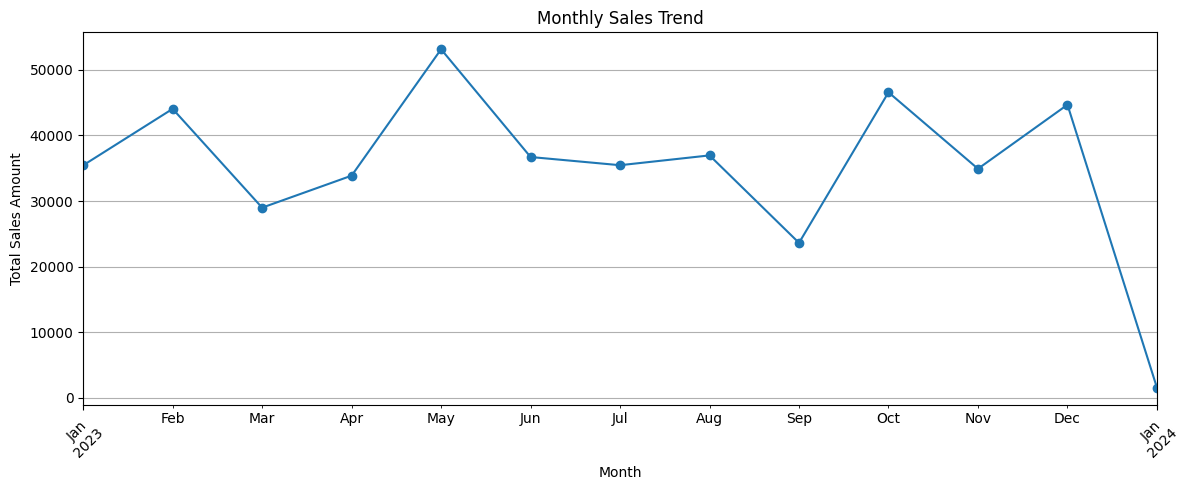

In [6]:

# Monthly Sales Trend

plt.figure(figsize=(12, 5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


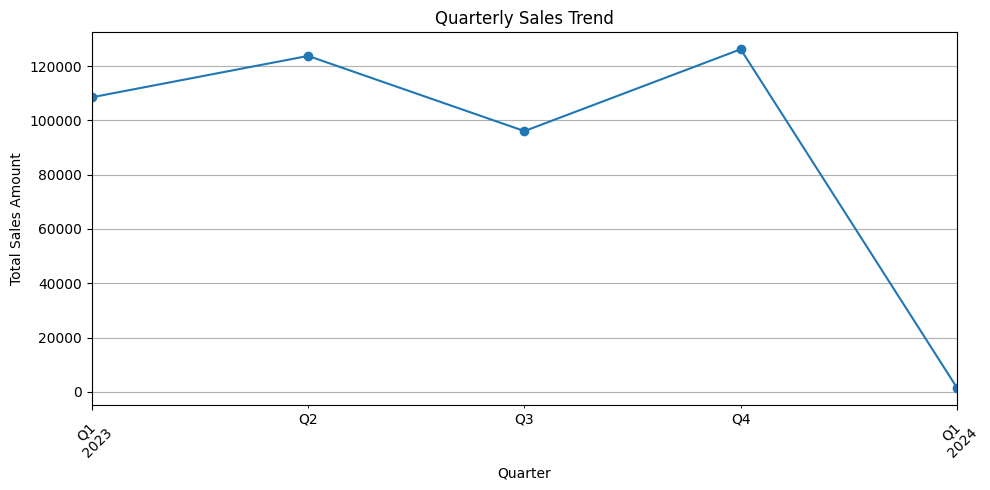

In [7]:

# Quarterly Sales Trend

plt.figure(figsize=(10, 5))

quarterly_sales.plot(kind='line', marker='o')

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()



## Time-Series Analysis

Time-series analysis was performed to understand
how retail sales change over time.

Monthly sales were calculated by grouping
transactions according to month.

Quarterly sales were calculated by grouping
transactions according to quarter.

Line charts were created to identify sales trends,
monthly fluctuations, and quarterly performance.

### Observations

1. Monthly sales show how revenue changes across months.
2. Quarterly sales help compare business performance across quarters.
3. Sales peaks and declines can help identify seasonal patterns.


In [8]:

# ==========================================
# STEP 4: CUSTOMER DEMOGRAPHICS ANALYSIS
# ==========================================

# Create age groups
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 60, 100],
    labels=['Below 20', '20-30', '31-40', '41-50', '51-60', 'Above 60']
)

# Display age group distribution
age_distribution = df['Age Group'].value_counts().sort_index()

print("CUSTOMER AGE GROUP DISTRIBUTION")
display(age_distribution)

# Display gender distribution
gender_distribution = df['Gender'].value_counts()

print("CUSTOMER GENDER DISTRIBUTION")
display(gender_distribution)


CUSTOMER AGE GROUP DISTRIBUTION


,count
Age Group,
Below 20,63
20-30,210
31-40,193
41-50,221
51-60,220
Above 60,93


CUSTOMER GENDER DISTRIBUTION


,count
Gender,
Female,510
Male,490


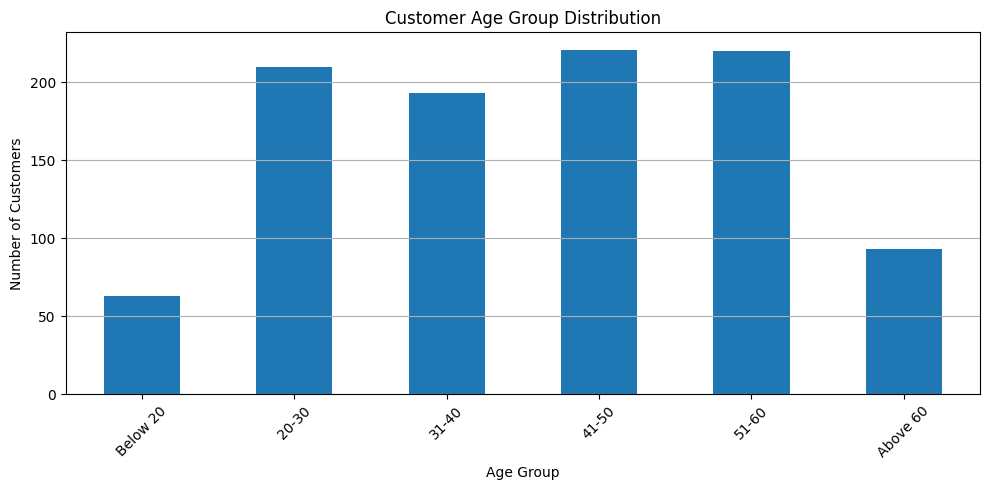

In [9]:

plt.figure(figsize=(10, 5))

age_distribution.plot(kind='bar')

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()


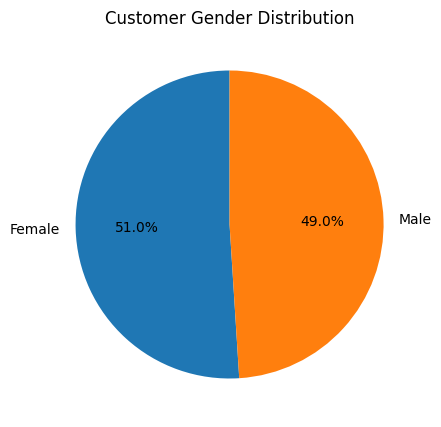

In [10]:

plt.figure(figsize=(7, 5))

gender_distribution.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Gender Distribution')
plt.ylabel('')

plt.show()



## Customer Demographics Analysis

Customer demographics were analysed using the Age
and Gender columns.

Age groups were created to understand the distribution
of customers across different age ranges.

A bar chart was used to visualise age-group distribution,
and a pie chart was used to represent gender distribution.

### Observations

1. The age-group chart shows which age ranges contribute most to the customer base.
2. The gender chart shows the proportion of male and female customers.
3. These insights can help the business plan targeted marketing campaigns.


In [11]:

# ==========================================
# STEP 5: PRODUCT ANALYSIS
# ==========================================

# Top 10 best-selling product categories
top_products = df.groupby('Product Category')['Quantity'].sum().sort_values(ascending=False).head(10)

print("TOP SELLING PRODUCT CATEGORIES")
display(top_products)

# Revenue by product category
category_revenue = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False)

print("REVENUE BY PRODUCT CATEGORY")
display(category_revenue)


TOP SELLING PRODUCT CATEGORIES


,Quantity
Product Category,
Clothing,894
Electronics,849
Beauty,771


REVENUE BY PRODUCT CATEGORY


,Total Amount
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


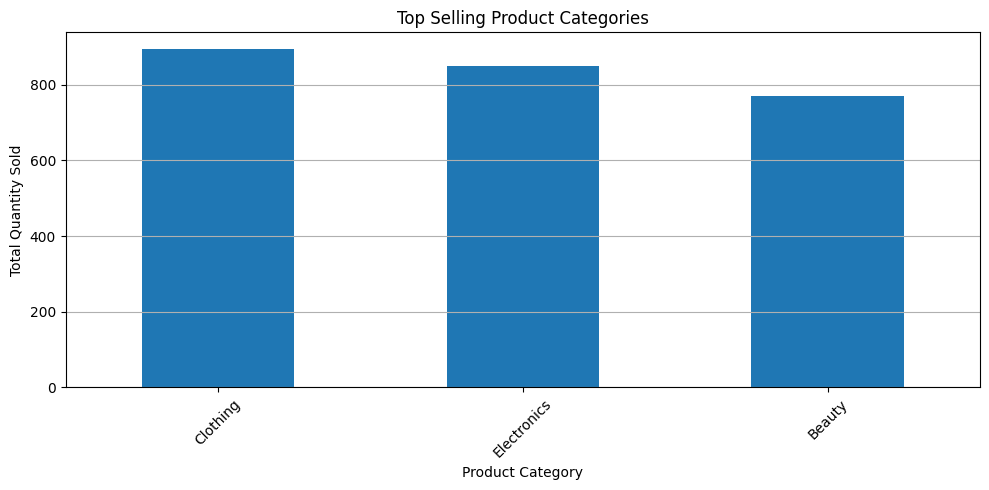

In [12]:

plt.figure(figsize=(10, 5))

top_products.plot(kind='bar')

plt.title('Top Selling Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()


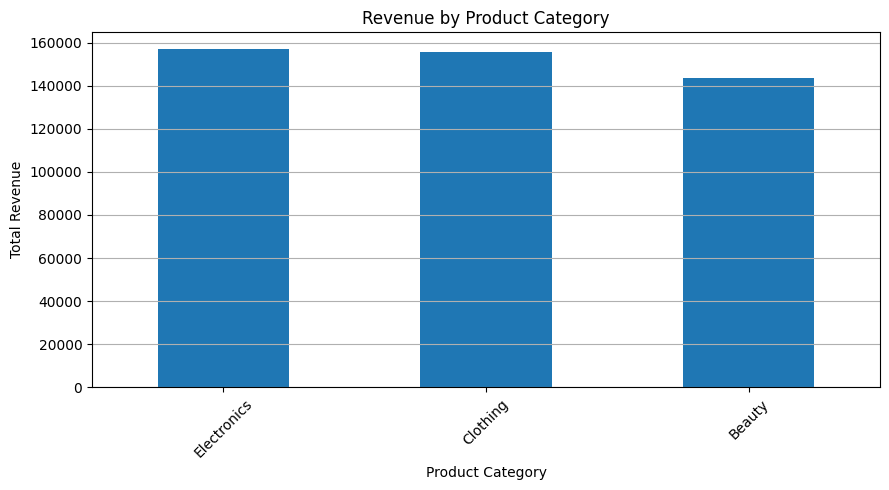

In [13]:

# Revenue by Product Category Chart

plt.figure(figsize=(9, 5))

category_revenue.plot(kind='bar')

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()



## Product Analysis

Product analysis was performed to identify the
best-selling product categories and their revenue
contribution.

### Observations

1. Clothing recorded the highest quantity sold, with 894 units.
2. Electronics generated the highest revenue of 156,905.
3. Clothing generated revenue of 155,580.
4. Beauty recorded the lowest quantity sold and revenue among the three categories.
5. The business should maintain sufficient clothing inventory and explore opportunities to increase electronics sales.


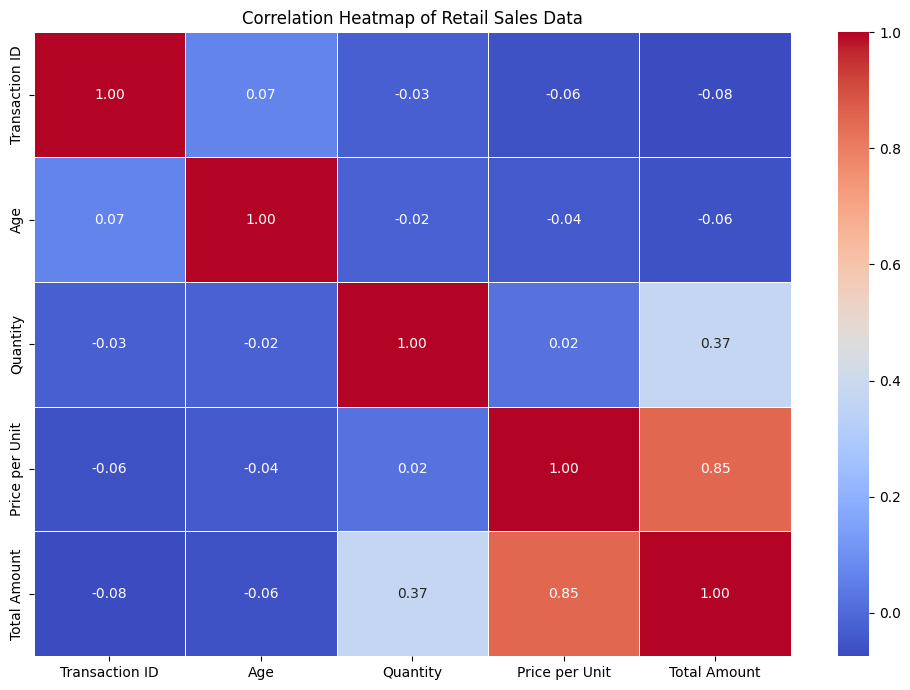

In [14]:

# ==========================================
# STEP 6: CORRELATION HEATMAP
# ==========================================

# Select numerical columns
numerical_data = df.select_dtypes(include=np.number)

# Calculate correlation
correlation_matrix = numerical_data.corr()

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Retail Sales Data')
plt.tight_layout()
plt.show()



## Correlation Heatmap Analysis

A correlation heatmap was created to understand
the relationships between numerical variables
in the retail sales dataset.

Correlation values range from -1 to +1.

- +1 indicates a strong positive relationship.
- -1 indicates a strong negative relationship.
- 0 indicates little or no linear relationship.

### Observations

The heatmap helps identify relationships between
customer age, quantity purchased, price per unit,
and total transaction amount.

These relationships can help the business
understand purchasing patterns.

### Detailed Findings

1. Price per Unit and Total Amount have a strong positive correlation of 0.85.
2. Quantity and Total Amount show a moderate positive correlation of 0.37.
3. Age and Total Amount have a very weak negative correlation of -0.06.
4. Age and Quantity show almost no linear correlation, with a value of -0.02.
5. Pricing and quantity are more closely associated with transaction revenue than customer age in this dataset.


AVERAGE SALES BY GENDER


,Total Amount
Gender,
Female,456.549020
Male,455.428571


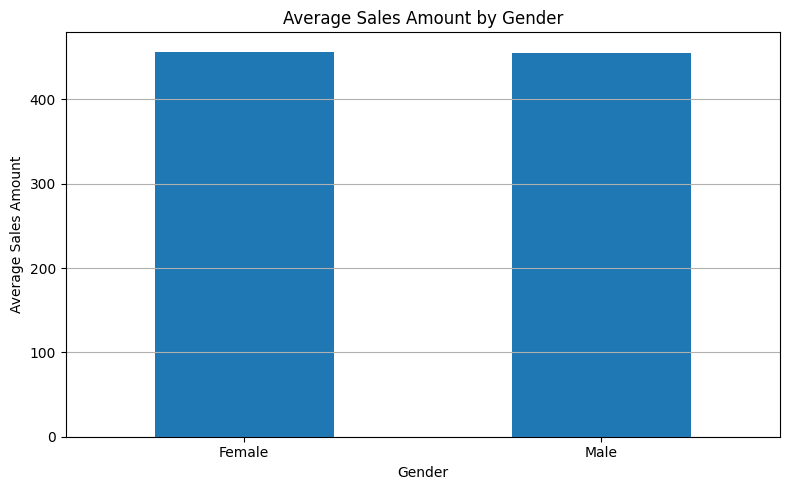

In [15]:

# ==========================================
# STEP 7: ADDITIONAL VISUALIZATION
# ==========================================

# Calculate average sales by gender
gender_sales = df.groupby('Gender')['Total Amount'].mean()

print("AVERAGE SALES BY GENDER")
display(gender_sales)

# Create bar chart
plt.figure(figsize=(8, 5))

gender_sales.plot(kind='bar')

plt.title('Average Sales Amount by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Sales Amount')
plt.xticks(rotation=0)
plt.grid(axis='y')

plt.tight_layout()
plt.show()



## Additional Visualization: Average Sales by Gender

A bar chart was created to compare the average
transaction amount between male and female customers.

### Observations

1. Female customers have an average transaction amount of approximately 456.55.
2. Male customers have an average transaction amount of approximately 455.43.
3. The difference between the two groups is very small.
4. The business has a nearly equal average transaction value across both genders.



# Conclusion

Exploratory Data Analysis was successfully performed
on the Retail Sales Dataset to understand sales trends,
customer demographics, and product performance.

The analysis revealed that:

1. Clothing recorded the highest quantity sold.
2. Electronics generated the highest revenue.
3. Female and male customers contributed almost equally
   to the customer base and average transaction value.
4. Monthly and quarterly sales showed variations over time.
5. Price per Unit had a strong positive correlation
   with Total Amount.

## Business Recommendations

1. Maintain sufficient inventory of clothing products
   because they have the highest sales quantity.
2. Focus on electronics marketing because this category
   generates the highest revenue.
3. Analyse monthly sales trends to improve inventory
   planning and promotional campaigns.
4. Target customers across different age groups
   using suitable marketing strategies.
5. Monitor pricing and transaction values to improve
   overall revenue performance.

Overall, this analysis provides useful insights that
can support better business decisions and improve
retail sales performance.
